# Laboratório — Animações 2D e 3D com Python/OpenGL

**Objetivo:** animar uma nave e um cubo, relacionando tempo, translação, rotação, escala e projeção.

**Duração:** 55–70 minutos. Execute em Jupyter local no computador do laboratório, com interface gráfica e driver OpenGL. A janela aparece fora do notebook. Colab e servidores sem tela não executam diretamente estas janelas.

O exemplo usa OpenGL clássico (contexto 2.1) para simplificar o estudo. Ele requer funções legadas; OpenGL moderno usa shaders e buffers. Não há iluminação: as cores das faces servem para identificar a orientação.
## Antes do código: observe os quadros

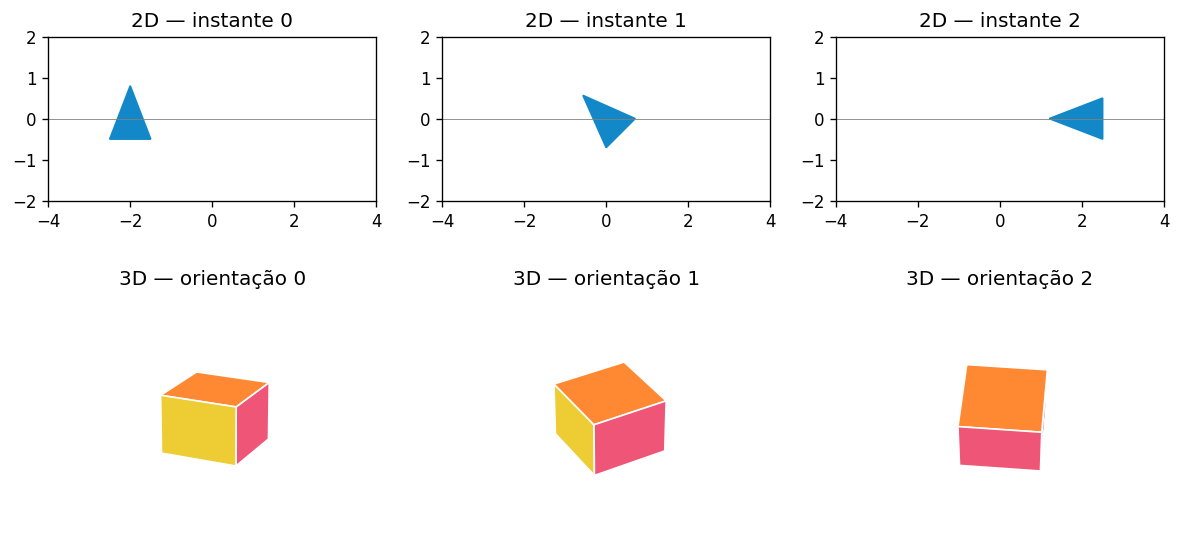

Na linha 2D mudamos posição e orientação. Na linha 3D observamos diferentes vistas do volume. A figura é uma ilustração dos conceitos, não uma captura da aplicação.

**Faça uma previsão:** o que muda se alterarmos apenas posição? E apenas ângulo?
## 1. Preparar o ambiente

Instale no mesmo ambiente do kernel. Após instalar, reinicie o kernel se necessário. O pacote de aceleração é opcional e não é necessário para esta aula.


In [1]:
%pip install pygame PyOpenGL

Note: you may need to restart the kernel to use updated packages.



## 2. Ler o estado de uma animação

O tempo é acumulado apenas enquanto a animação não está pausada. A posição oscila entre −AMPLITUDE e +AMPLITUDE. PERIODO é o tempo de uma ida e volta completa. GIRO é medido em graus por segundo. A escala oscila entre 0,8 e 1,2.

Observe o trecho `estado`: ele calcula o que muda. As funções `nave` e `cubo` descrevem a forma. `executar` conecta eventos, atualização e desenho.

**Ordem:** as chamadas translação → rotação → escala produzem, sobre o vértice local, escala → rotação → translação. `glPushMatrix` e `glPopMatrix` isolam as transformações do objeto. `glLoadIdentity` evita acumular transformações entre quadros.


In [2]:
import math
import pygame
from OpenGL.GL import *
from OpenGL.GLU import gluPerspective

# Parâmetros para experimentar.
FPS = 60
VELOCIDADE = 1.0
AMPLITUDE = 2.5
PERIODO = 6.0
GIRO = 60.0  # graus por segundo


# Tempo (s), posição X, ângulo (graus), escala.
QUADROS_CHAVE = [
    (0.0, -2.5,   0.0, 1.0),
    (2.0,  0.0,  90.0, 1.5),
    (4.0,  2.5, 180.0, 1.0),
    (6.0,  0.0, 270.0, 0.8),
    (8.0, -2.5, 360.0, 1.0)
]

def interpolar(inicio, fim, progresso):
    """Calcula um valor entre início e fim."""
    return inicio + (fim - inicio) * progresso

def estadoChave(t, modo):
    """Calcula as transformações entre dois quadros-chave."""

    # Repetir a animação a cada 8 segundos.
    duracao = QUADROS_CHAVE[-1][0]
    tempo = t % duracao

    # Encontrar o intervalo que contém o tempo atual.
    for i in range(len(QUADROS_CHAVE) - 1):
        chave_inicio = QUADROS_CHAVE[i]
        chave_fim = QUADROS_CHAVE[i + 1]

        t_inicio, x_inicio, ang_inicio, esc_inicio = chave_inicio
        t_fim, x_fim, ang_fim, esc_fim = chave_fim

        if t_inicio <= tempo < t_fim:

            # 0 = início do intervalo; 1 = fim do intervalo.
            progresso = (tempo - t_inicio) / (t_fim - t_inicio)

            x = interpolar(x_inicio, x_fim, progresso)
            angulo = interpolar(ang_inicio, ang_fim, progresso)
            escala = interpolar(esc_inicio, esc_fim, progresso)

            # Manter os modos de demonstração do código original.
            if modo not in (1, 4):
                x = 0.0

            if modo not in (2, 4):
                angulo = 0.0

            if modo not in (3, 4):
                escala = 1.0

            return x, angulo, escala

def estadoChave2(t, modo):
    """Animação por quadros-chave SEM suavização."""

    duracao = QUADROS_CHAVE[-1][0]
    tempo = t % duracao

    for i in range(len(QUADROS_CHAVE) - 1):
        t_inicio, x_inicio, ang_inicio, esc_inicio = QUADROS_CHAVE[i]
        t_fim, x_fim, ang_fim, esc_fim = QUADROS_CHAVE[i + 1]

        if t_inicio <= tempo < t_fim:

            # Progresso avança proporcionalmente ao tempo.
            # Não aplicamos uma curva de suavização.
            progresso = (tempo - t_inicio) / (t_fim - t_inicio)

            x = interpolar(x_inicio, x_fim, progresso)
            angulo = interpolar(ang_inicio, ang_fim, progresso)
            escala = interpolar(esc_inicio, esc_fim, progresso)

            if modo not in (1, 4):
                x = 0.0

            if modo not in (2, 4):
                angulo = 0.0

            if modo not in (3, 4):
                escala = 1.0

            return x, angulo, escala
        
def estado(t, modo):
    """Transformações calculadas a partir do tempo da animação."""
    x = AMPLITUDE * math.sin(2 * math.pi * t / PERIODO) if modo in (1, 4) else 0
    angulo = (GIRO * t) % 360 if modo in (2, 4) else 0
    escala = 1 + 0.2 * math.sin(2 * math.pi * t / 2) if modo in (3, 4) else 1
    return x, angulo, escala

def nave():
    glColor3f(0.1, 0.8, 1.0)
    glBegin(GL_TRIANGLES)
    for ponto in [(0, 0.8), (-0.5, -0.5), (0.5, -0.5)]:
        glVertex2f(*ponto)
    glEnd()
    glColor3f(1.0, 0.65, 0.15)
    glBegin(GL_TRIANGLES)
    for ponto in [(-0.2, -0.5), (0.2, -0.5), (0, -0.9)]:
        glVertex2f(*ponto)
    glEnd()

def cubo():
    vertices = [(-1,-1,-1),(1,-1,-1),(1,1,-1),(-1,1,-1),
                (-1,-1,1),(1,-1,1),(1,1,1),(-1,1,1)]
    faces = [(0,1,2,3),(4,7,6,5),(0,4,5,1),
             (3,2,6,7),(0,3,7,4),(1,5,6,2)]
    cores = [(0.2,0.6,1),(1,0.5,0.2),(0.3,0.8,0.4),
             (0.9,0.3,0.5),(0.7,0.4,0.9),(1,0.8,0.2)]
    # Dois triângulos por face.
    glBegin(GL_TRIANGLES)
    for face, cor in zip(faces, cores):
        glColor3f(*cor)
        for indice in (face[0],face[1],face[2],face[0],face[2],face[3]):
            glVertex3f(*vertices[indice])
    glEnd()

def configurar_projecao(tipo, perspectiva):
    glMatrixMode(GL_PROJECTION)
    glLoadIdentity()
    if tipo == '3D' and perspectiva:
        gluPerspective(45, 960 / 640, 0.1, 100)
    else:
        glOrtho(-6, 6, -4, 4, 0.1, 100)
    glMatrixMode(GL_MODELVIEW)

def executar(tipo='2D', limite_segundos=None):
    if tipo not in ('2D', '3D'):
        raise ValueError("Escolha '2D' ou '3D'.")
    pygame.init()
    try:
        # Contexto clássico: requer suporte às funções legadas do OpenGL.
        pygame.display.gl_set_attribute(pygame.GL_CONTEXT_MAJOR_VERSION, 2)
        pygame.display.gl_set_attribute(pygame.GL_CONTEXT_MINOR_VERSION, 1)
        pygame.display.gl_set_attribute(pygame.GL_DEPTH_SIZE, 24)
        pygame.display.set_mode((960, 640), pygame.DOUBLEBUF | pygame.OPENGL)
        glViewport(0, 0, 960, 640)
        glClearColor(0.04, 0.06, 0.12, 1)
        if tipo == '3D':
            glEnable(GL_DEPTH_TEST)
        else:
            glDisable(GL_DEPTH_TEST)
        relogio = pygame.time.Clock()
        t = 0.0
        tempo_real = 0.0
        pausado = False
        fator = VELOCIDADE
        modo = 4
        perspectiva = True
        rodando = True
        while rodando:
            # tick retorna milissegundos; convertemos para segundos.
            dt = relogio.tick(FPS) / 1000.0
            tempo_real += dt
            for evento in pygame.event.get():
                if evento.type == pygame.QUIT:
                    rodando = False
                elif evento.type == pygame.KEYDOWN:
                    tecla = evento.key
                    if tecla == pygame.K_ESCAPE: rodando = False
                    elif tecla == pygame.K_SPACE: pausado = not pausado
                    elif tecla == pygame.K_r: t = 0.0
                    elif tecla == pygame.K_UP: fator = min(4, fator + 0.25)
                    elif tecla == pygame.K_DOWN: fator = max(0.25, fator - 0.25)
                    elif tecla == pygame.K_p: perspectiva = not perspectiva
                    elif tecla in (pygame.K_1,pygame.K_2,pygame.K_3,pygame.K_4):
                        modo = tecla - pygame.K_0
            if limite_segundos is not None and tempo_real >= limite_segundos:
                rodando = False
            if not rodando: break
            if not pausado:
                t += dt * fator
            # x, angulo, escala = estado(t, modo)
            # x, angulo, escala = estadoChave(t, modo)
            x, angulo, escala = estadoChave2(t, modo)

            configurar_projecao(tipo, perspectiva)
            glClear(GL_COLOR_BUFFER_BIT | GL_DEPTH_BUFFER_BIT)
            glLoadIdentity()
            # Afasta a cena da posição do observador.
            glTranslatef(0, 0, -12)
            glPushMatrix()
            glTranslatef(x, 0, 1)
            if tipo == '2D':
                glRotatef(angulo, 0, 0, 1)
                # RAIO = 2.5
                # glTranslatef(RAIO, 0, 0)
            else:
                glRotatef(20 + angulo, 1, 0, 0)
                glRotatef(30 + angulo * 0.7, 0, 1, 0)
            glScalef(escala, escala, escala)
            if tipo == '2D': nave()
            else: cubo()
            glPopMatrix()
            pygame.display.flip()
            pygame.display.set_caption(
                f'{tipo} | modo {modo} | {fator:.2f}x | '
                f'{relogio.get_fps():.0f} FPS | ESPACO pausa | R reinicia | '
                '1-4 modos | setas velocidade | P projecao | ESC sair')
    finally:
        pygame.quit()




pygame 2.6.1 (SDL 2.28.4, Python 3.12.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


## 3. Explorar a nave 2D

Execute a próxima célula. A execução ficará ocupada enquanto a janela estiver aberta. Feche com ESC antes de abrir a cena 3D.

| Tecla | Ação |
|---|---|
| 1 | Só translação |
| 2 | Só rotação |
| 3 | Só escala |
| 4 | Combinar |
| Espaço | Pausar/continuar |
| R | Reiniciar o tempo |
| ↑ / ↓ | Aumentar/diminuir a velocidade |
| ESC | Fechar |


In [3]:
executar('2D')


## 4. Explorar o cubo 3D

O buffer de profundidade permite que faces próximas escondam faces distantes. A cena fica à frente do observador, em Z negativo. Pressione **P** para alternar perspectiva e ortográfica. Os enquadramentos têm escalas diferentes; compare a relação entre distância e tamanho, e não apenas o tamanho inicial do cubo.

Os ângulos iniciais de 20° e 30° deixam várias faces visíveis mesmo quando o giro está desligado.


In [4]:
executar('3D')

## 4.1. Animar a câmera: observar uma cena parada

Imagine caminhar ao redor de uma escultura: ela permanece parada, mas você vê outras faces. Aqui, três cubos e uma grade permanecem fixos no mundo. Apenas o observador se move.

| Tecla | Movimento | Observe |
|---|---|---|
| 1 | Órbita ao redor do cubo central | Faces e sobreposição dos objetos mudam |
| 2 | Deslocamento lateral com orientação fixa | Objetos próximos e distantes apresentam paralaxe |
| 3 | Aproximação e afastamento (dolly) | Na perspectiva, o tamanho aparente muda |
| P | Alternar perspectiva e ortográfica | Na ortográfica, aproximar não aumenta o tamanho |
| Espaço | Pausar/continuar | Inspecione o enquadramento |
| R | Reiniciar | Retorna ao início do percurso |
| ↑ / ↓ | Ajustar velocidade | Altera o ritmo do movimento |
| ESC | Fechar | Libera a célula |

**Como funciona:** `gluLookAt` recebe a posição da câmera, o ponto para onde ela olha e a direção que representa "para cima". A cada quadro, calculamos uma nova posição usando o tempo. A matriz de visualização é aplicada antes das transformações dos objetos.

Na órbita e no dolly, a câmera olha para a origem. No deslocamento lateral, o alvo acompanha a posição X da câmera para manter sua orientação fixa. O dolly muda a distância; o campo de visão permanece em 45°. Exemplos de aplicação: apresentação de produtos, câmeras de jogos e percursos virtuais.

Execute primeiro a célula com as funções originais. Feche qualquer janela anterior antes de abrir esta demonstração.


In [5]:
from OpenGL.GLU import gluLookAt

RAIO_CAMERA = 12.0
PERIODO_CAMERA = 12.0

def posicao_camera(t, modo):
    """Retorna posição do observador e alvo, em coordenadas do mundo."""
    fase = 2 * math.pi * t / PERIODO_CAMERA
    if modo == 1:  # Órbita: percorre um círculo olhando para o centro.
        olho = (RAIO_CAMERA * math.sin(fase), 5.0,
                RAIO_CAMERA * math.cos(fase))
        alvo = (0.0, 0.0, 0.0)
    elif modo == 2:  # Travelling lateral: posição e alvo avançam juntos.
        x = 5.0 * math.sin(fase)
        olho = (x, 4.0, 12.0)
        alvo = (x, 0.0, 0.0)
    else:  # Dolly: muda a distância sem alterar o campo de visão.
        distancia = 10.0 + 4.0 * math.cos(fase)
        olho = (0.0, 3.0, distancia)
        alvo = (0.0, 0.0, 0.0)
    return olho, alvo

def desenhar_cena_camera():
    # Grade fixa: referência espacial para perceber o movimento.
    glColor3f(0.3, 0.35, 0.42)
    glBegin(GL_LINES)
    for i in range(-8, 9):
        glVertex3f(i, -1.05, -8)
        glVertex3f(i, -1.05, 8)
        glVertex3f(-8, -1.05, i)
        glVertex3f(8, -1.05, i)
    glEnd()
    # Cubos fixos em profundidades diferentes: evidenciam a paralaxe.
    for x, z, tamanho in [(0, 0, 1.0), (-3, -3, 0.8), (3, 3, 0.6)]:
        glPushMatrix()
        glTranslatef(x, -1.0 + tamanho, z)
        glScalef(tamanho, tamanho, tamanho)
        cubo()
        glPopMatrix()

def executar_camera(limite_segundos=None):
    pygame.init()
    try:
        pygame.display.gl_set_attribute(pygame.GL_CONTEXT_MAJOR_VERSION, 2)
        pygame.display.gl_set_attribute(pygame.GL_CONTEXT_MINOR_VERSION, 1)
        pygame.display.gl_set_attribute(pygame.GL_DEPTH_SIZE, 24)
        pygame.display.set_mode((960, 640), pygame.DOUBLEBUF | pygame.OPENGL)
        glViewport(0, 0, 960, 640)
        glClearColor(0.04, 0.06, 0.12, 1)
        glEnable(GL_DEPTH_TEST)
        relogio = pygame.time.Clock()
        t = tempo_real = 0.0
        fator = 1.0
        modo = 1
        pausado = False
        perspectiva = True
        rodando = True
        nomes = {1: 'Orbita', 2: 'Lateral', 3: 'Dolly'}
        while rodando:
            dt = relogio.tick(FPS) / 1000.0
            tempo_real += dt
            for evento in pygame.event.get():
                if evento.type == pygame.QUIT:
                    rodando = False
                elif evento.type == pygame.KEYDOWN:
                    tecla = evento.key
                    if tecla == pygame.K_ESCAPE: rodando = False
                    elif tecla == pygame.K_SPACE: pausado = not pausado
                    elif tecla == pygame.K_r: t = 0.0
                    elif tecla == pygame.K_p: perspectiva = not perspectiva
                    elif tecla == pygame.K_UP: fator = min(4.0, fator + 0.25)
                    elif tecla == pygame.K_DOWN: fator = max(0.25, fator - 0.25)
                    elif tecla in (pygame.K_1, pygame.K_2, pygame.K_3):
                        modo = tecla - pygame.K_0
                        t = 0.0
            if limite_segundos is not None and tempo_real >= limite_segundos:
                rodando = False
            if not rodando:
                break
            if not pausado:
                t += dt * fator
            configurar_projecao('3D', perspectiva)
            glClear(GL_COLOR_BUFFER_BIT | GL_DEPTH_BUFFER_BIT)
            glMatrixMode(GL_MODELVIEW)
            glLoadIdentity()
            olho, alvo = posicao_camera(t, modo)
            # Substitui o afastamento fixo por uma visualização animada.
            gluLookAt(*olho, *alvo, 0.0, 1.0, 0.0)
            desenhar_cena_camera()
            pygame.display.flip()
            projecao = 'Perspectiva' if perspectiva else 'Ortografica'
            pygame.display.set_caption(
                f'Camera: {nomes[modo]} | {projecao} | {fator:.2f}x | '
                '1-3 movimentos | P projecao | ESPACO pausa | R reinicia | ESC sair')
    finally:
        pygame.quit()


In [6]:
executar_camera()

### Experimento: câmera e objeto

1. No modo órbita, pause em duas posições e compare as faces visíveis do cubo central. Os vértices do cubo mudaram de posição no mundo?
2. No modo lateral, compare o deslocamento aparente dos cubos próximo e distante. Explique a paralaxe observada.
3. No modo dolly, alterne **P** e compare o tamanho aparente durante o percurso. Diferencie aproximação da câmera e escala do objeto.




## 5. Atividade prática — quatro exercícios

### Exercício 1 — Nova trajetória 2D
Modifique a atualização para a nave percorrer também o eixo Y. Crie uma trajetória diagonal ou uma elipse. Para uma elipse, use seno em X e cosseno em Y com o mesmo período. A função `estado` deverá retornar também `y`; atualize seu desempacotamento e `glTranslatef(x, y, 0)`. Mantenha o objeto dentro da janela.

### Exercício 2 — Tempo e FPS
Execute em 30 e 60 FPS, mantendo GIRO e VELOCIDADE iguais. Cronometre uma volta no modo 2. Depois dobre GIRO e repita. Registre FPS observado, duração aproximada da volta e percepção de fluidez. Com GIRO=60, uma volta ideal leva 6 s; com GIRO=120, 3 s. A meta de FPS pode não ser atingida. Explique por que `dt` ajuda a preservar a velocidade.

### Exercício 3 — Eixos e ordem em 3D
No modo 2, altere as chamadas de rotação para girar separadamente em X, Y e Z. Registre o que cada eixo faz. Depois, no modo 4, troque a ordem de translação e rotação e compare giro próprio e órbita. A órbita pode levar o objeto para perto ou para trás da câmera: reduza AMPLITUDE ou afaste a cena se necessário.

### Exercício 4 — Cena autoral
Crie um satélite, logotipo ou veículo simples. Combine pelo menos duas transformações e ofereça pausa e reinício. Em 3D, acrescente outro objeto com `glPushMatrix`/`glPopMatrix` próprios. Explique o pivô, o ritmo e a projeção escolhidos.

**Entrega:** notebook com as modificações, duas capturas (2D e 3D) e respostas breves. Se adicionar capturas ao notebook, use anexos ou incorpore a imagem para evitar caminhos quebrados.

**Avaliação (10 pontos):** trajetória 2D (2); comparação de tempo/FPS (2); análise de eixos/ordem (3); cena autoral funcional e explicada (3).
## Registro dos resultados

| Teste | Configuração | O que observei | Explicação |
|---|---|---|---|
| Trajetória 2D | | | |
| 30 FPS / 60 FPS | | | |
| Rotação X / Y / Z | | | |
| Cena autoral | | | |


## Referências

- [Relógio do Pygame](https://www.pygame.org/docs/ref/time.html)
- [Funções do PyOpenGL](https://pyopengl.sourceforge.net/documentation/manual-3.0/index.html)
- [OpenGL clássico e compatibilidade](https://wikis.khronos.org/opengl/Legacy_OpenGL)